# Modelagem de plano de previdência privada

O saldo da conta varia de acordo com:


*   taxa de juros mensal $r$;
*   o próprio saldo $s(t)$.

Modela-se pela fórmula
$$\dfrac{d}{dt}s(t) = r \, s(t)  + k$$
> onde $k$ sãos os depósitos mensais.


## Solução simbólica

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
t,r,k,s0 = sp.symbols("t r k s_0")

In [ ]:
s = sp.Function("s")
s = s(t)
s

s(t)

In [ ]:
s1 = sp.Derivative(s,t)
s1

Derivative(s(t), t)

In [ ]:
ode = sp.Eq(s1 , r*s + k)
ode

Eq(Derivative(s(t), t), k + r*s(t))

In [ ]:
s_sol = sp.dsolve(ode)
s_sol

Eq(s(t), (-k + exp(r*(C1 + t)))/r)

## Solução com números
Sejam os valores abaixo definidos:

In [ ]:
s0 = 0
r = 0.0025
k = 1000
dt = 40

In [ ]:
t= sp.symbols("t")
s = sp.Function("s")

In [ ]:
ode = sp.Eq(sp.Derivative(s(t),t) , r*s(t) + k)
ode

Eq(Derivative(s(t), t), 0.0025*s(t) + 1000)

In [ ]:
s_sol = sp.dsolve(ode,s(t),ics={s(0):s0})
s_sol.args[1]

400000.0*exp(0.0025*t) - 400000.0

In [ ]:
s_depositado = sp.lambdify(t,s_sol.args[1])
s_aposentado = s_depositado(dt*12)
juro = s_aposentado - k*dt*12
print("O saldo ao se aposentar será de: ",int(s_aposentado/1000),"mil reais")
print("O valor total depositado foi de: ",int(k*dt*12/1000),"mil reais")
print("O valor dos juros são: ",int(juro/1000),"mil reais")

O saldo ao se aposentar será de:  928 mil reais
O valor total depositado foi de:  480 mil reais
O valor dos juros são:  448 mil reais


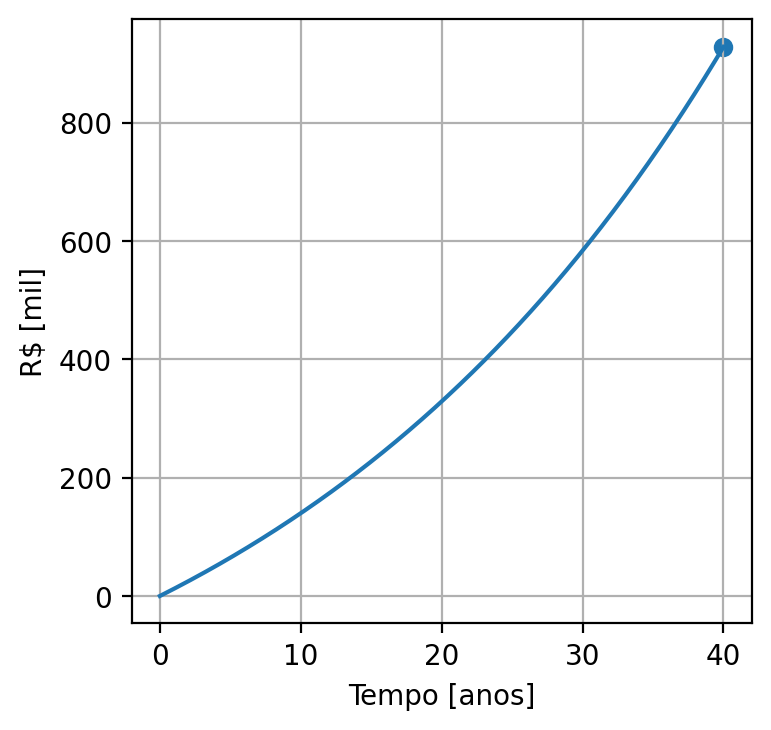

In [206]:
tt = np.arange(0,dt*12+1,1)
plt.figure(dpi=200,figsize=(4,4))
plt.plot(tt/12,s_depositado(tt)/1000)
plt.grid()
plt.xlabel('Tempo [anos]')
plt.ylabel('R$ [mil]')
plt.scatter(dt,s_depositado(dt*12)/1000)
plt.show()